# Tutorial 8 — Oscillator strengths

*Part 4 — Going further · tutorial 8 of 9 · previous: [07 More data](07_more_data.ipynb) · next: [09 More models](09_more_models.ipynb)*

The oscillator strength f₀ₖ of the transition from the ground state S0 to an
excited state Sk says how strongly that state absorbs light: it sets the heights of
the bands of an absorption spectrum. X-MACE can learn oscillator strengths
**directly**, from labels of f alone, for example from TDDFT outputs that list
excitation energies and oscillator strengths but no transition dipole vectors.

This tutorial covers:

1. what is learned, and how;
2. preparing data, including files that store f under another key, and splitting them;
3. a model trained on oscillator strengths only (no energies, no forces);
4. a model trained on energies, forces and oscillator strengths together, and an
   absorption spectrum from it;
5. a committee with uncertainties;
6. adding oscillator strengths to a model you already trained;
7. the same on a GPU cluster, starting from MACE-POLAR-1 (SLURM);
8. checking your installation, and troubleshooting.

Every training run is a complete command in a `%%bash` cell, run from
`tutorials/xmace/work/oscillator`. The helper scripts are in `tutorials/xmace/tools/`:
`prepare_osc_data.py` (convert and split), `osc_committee.py` (committee
predictions) and `train_committee_osc.slurm` (cluster job).

**Requirements:** `work/so2_train.xyz` and `work/so2_test.xyz` from Tutorial 2, and
`work/so2.model` from Tutorial 3 (section 6). Runtime: about 15 minutes on 2 CPU
cores.

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase.io
import matplotlib.pyplot as plt
import numpy as np

TUTORIAL = Path.cwd()
WORK = TUTORIAL / "work"
RUN = WORK / "oscillator"
RUN.mkdir(parents=True, exist_ok=True)
os.environ["DEVICE"] = "cpu"  # cpu or cuda, used by the commands below
assert (WORK / "so2_train.xyz").exists(), "run Tutorial 2 first"

## 1. What is learned

For a transition from S0 to Sk, with excitation energy ΔE₀ₖ and transition dipole
**μ**₀ₖ (atomic units),

  f₀ₖ = 2/3 · ΔE₀ₖ · |**μ**₀ₖ|².

f is a number ≥ 0 that does not change when the molecule is rotated, and it has no
phase (the sign of **μ**₀ₖ cancels). So X-MACE predicts it like an invariant
property:

  f₀ₖ = scale₀ₖ · softplus(Σ_atoms readout₀ₖ(atom features)).

* The **softplus** keeps it non-negative.
* The **scale** per transition is the rms of that transition's labels in the training
  data (logged at the start of training), so the network works with numbers of order
  one, whatever the magnitude of the data.
* The loss is `oscillator_strengths_weight` · MSE(f / scale): weak and bright
  transitions count alike.

**Which transitions.** By default, one per other state of the ground state's
multiplicity: S0 → S1, …, S(n−1) with n singlets (`--osc_num` sets fewer). The
number of states, `--n_energies` (or `--states`), is therefore the number of
oscillator strengths plus one. For SO2 with 4 singlets and 3 triplets, there are 3:
S0 → S1, S2, S3.

The LVC data of Tutorial 2 has energies and transition dipoles, so we compute the
reference oscillator strengths from them. With real data you would take them from
the quantum-chemistry output.

658 training frames; f per transition: mean [0.0029 0.0021 0.0138], max [0.0068 0.0061 0.0207]


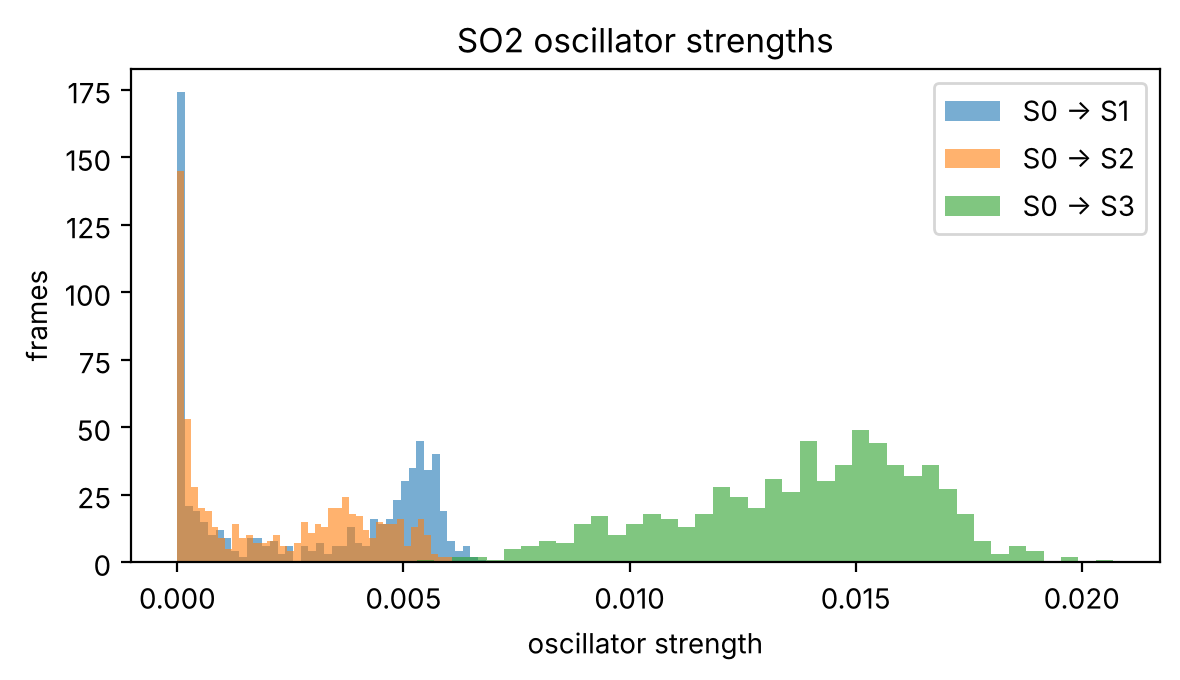

In [2]:
HARTREE = 27.211386  # eV
BOHR = 0.529177  # Å


def oscillator_strengths(atoms):
    """f(S0 -> S1..S3) of an SO2 frame (energies in eV, dipoles in e·Å)."""
    energies = np.asarray(atoms.info["REF_energy"], dtype=float).reshape(-1)
    transition = np.asarray(atoms.info["REF_dipoles"])[7:]  # after 7 permanent dipoles
    # the singlet pairs come first: (0,1), (0,2), (0,3), ...
    return np.array(
        [2 / 3 * (energies[k] - energies[0]) / HARTREE * np.sum((transition[k - 1] / BOHR) ** 2)
         for k in (1, 2, 3)]
    )


train = ase.io.read(WORK / "so2_train.xyz", ":")
test = ase.io.read(WORK / "so2_test.xyz", ":")
f_train = np.array([oscillator_strengths(a) for a in train])
print(f"{len(train)} training frames; f per transition: mean {f_train.mean(0).round(4)}, "
      f"max {f_train.max(0).round(4)}")

fig, ax = plt.subplots(figsize=(6, 3.5))
for k in range(3):
    ax.hist(f_train[:, k], bins=40, alpha=0.6, label=f"S0 → S{k + 1}")
ax.set(xlabel="oscillator strength", ylabel="frames", title="SO2 oscillator strengths")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Preparing the data

X-MACE reads oscillator strengths from `atoms.info["REF_oscillator_strengths"]`, an
array [f(S0→S1), …, f(S0→Sₙ)] per frame (`--oscillator_strengths_key` for another
key). A leading 0 for S0 itself is also accepted.

Data sets are not always in that form. Here is one as such data often comes: the
oscillator strengths stored **under `REF_energy`**, as a nested list, no energies
or forces, saved with a Windows byte-order mark and line endings, and cut off in the
middle of the last frame.

In [3]:
lines = []
for atoms in train + test:
    f = oscillator_strengths(atoms)
    lines.append(f"{len(atoms)}")
    lines.append('Properties=species:S:1:pos:R:3 REF_energy="_JSON [['
                 + ", ".join(f"{x:.8f}" for x in f) + ']]" pbc="F F F"')
    for symbol, (x, y, z) in zip(atoms.get_chemical_symbols(), atoms.positions):
        lines.append(f"{symbol:2s} {x:16.8f} {y:16.8f} {z:16.8f}")
lines = lines[:-2]  # an incomplete last frame
raw = RUN / "so2_osc_raw.xyz"
raw.write_bytes(b"\xef\xbb\xbf" + "\r\n".join(lines).encode() + b"\r\n")
print(open(raw, encoding="utf-8-sig").read().splitlines()[1])

Properties=species:S:1:pos:R:3 REF_energy="_JSON [[0.00221557, 0.00256539, 0.01752472]]" pbc="F F F"


ASE cannot read this file (the byte-order mark), and X-MACE would take the values
for energies. `tools/prepare_osc_data.py` fixes both, and splits the frames into
training, validation and test sets (random, seeded; default 90 / 5 / 5 %). It also
writes `e0s.txt`, an `--E0s` dictionary with every element of the data, and
`n_osc.txt`, the number of oscillator strengths. It reads one frame at a time, so
files of any size are fine.

In [4]:
%%bash
cd work/oscillator
python ../../tools/prepare_osc_data.py so2_osc_raw.xyz --out_dir osc_data \
    --valid_fraction 0.1 --test_fraction 0.15 --seed 1
echo; sed -n 2p osc_data/train.xyz | cut -c1-110

807 frames: train 605, valid 81, test 121 -> osc_data/
REF_oscillator_strengths: 3 values per frame 

(use --n_energies=4)
mean per transition: [0.003  0.0021 0.0138]
max per transition:  [0.0068 0.0061

 0.0207]
elements: O S
--E0s="{8: 0.0, 16: 0.0}" (also in osc_data/e0s.txt)


Properties=species:S:1:pos:R:3 REF_oscillator_strengths="0.00221557 0.00256539 0.01752472" pbc="F F 

F"


Options: `--from_key` (default `REF_energy`; `REF_oscillator_strengths` when the
values are already under the right key, to only clean and split), `--to_key`,
`--valid_fraction`, `--test_fraction`, `--seed`. The split is per frame; if your data
has several geometries of one molecule, split by molecule instead, or the test error
is optimistic.

## 3. Oscillator strengths only

The prepared files have no energies or forces. Train with

* `--compute_oscillator_strengths` and `--n_energies` = number of oscillator
  strengths + 1;
* `--energy_weight=0 --forces_weight=0`: then no forces are computed in training (the
  log says so), which saves one backward pass per state;
* `--E0s` from `e0s.txt` (the values do not matter: energies are not trained), or
  `--E0s=foundation` with a foundation model.

The log warns that it found no energies; that is expected.

In [5]:
%%bash
cd work/oscillator
mace_run_train \
    --name=f_only \
    --train_file=osc_data/train.xyz --valid_file=osc_data/valid.xyz --test_file=osc_data/test.xyz \
    --model=ExcitedMACE --n_energies=$(( $(cat osc_data/n_osc.txt) + 1 )) \
    --compute_oscillator_strengths \
    --E0s="$(cat osc_data/e0s.txt)" --energy_weight=0 --forces_weight=0 \
    --r_max=5.0 --hidden_irreps="32x0e + 32x1o" --MLP_irreps=16x0e \
    --num_interactions=2 --correlation=2 \
    --batch_size=10 --valid_batch_size=32 --max_num_epochs=40 --lr=0.01 --seed=1 \
    --error_table=EnergyNacsDipoleMAE --device=$DEVICE --default_dtype=float64 \
    > f_only.out 2>&1
grep -h "oscillator strengths=\|scale (rms)\|not computed" logs/f_only_run-1.log | cut -d" " -f4- | sort -u
grep -A5 "Error-table on TEST" logs/f_only_run-1.log | tail -n 4

Excited-state model on a ScaleShiftMACE backbone with heads Default (4 states, NACs=0 (raw), SOCs=0,

 dipoles=0, oscillator strengths=3 (S0 -> S1..S3))
ExcitedMACE: 4 states, NACs=0 (raw), SOCs=0, dipo

les=0, oscillator strengths=3 (S0 -> S1..S3), coupling parity=both, pair repulsion=off, backbone=Sca

leShiftMACE, long range=shared
Head Default: 4 states, NACs=0 (raw), SOCs=0, dipoles=0, oscillator s

trengths=3 (S0 -> S1..S3)
Head Default: 4 states, NACs=0 (raw), SOCs=0, dipoles=0, oscillator streng

ths=3 (S0 -> S1..S3); interaction energy scale 1.0000, shift per state 0.0000, 0.0000, 0.0000, 0.000

... (5 outputs left out)

------+---------------------+-------------------+
| Default_Default_Default |     N/A     |        N

/A         |       N/A       |     N/A     |       N/A        |       N/A        |         N/A      

   |          0.63     |
+-------------------------+-------------+--------------------+-------------

----+-------------+------------------+------------------+---------------------+-------------------+


The last column is the test MAE of f (×10⁻³); the energy and force columns are
`N/A` because there are none. A parity plot with the ASE calculator, which returns
`results["oscillator_strengths"]`:

transitions of the model: [(0, 1), (0, 2), (0, 3)]


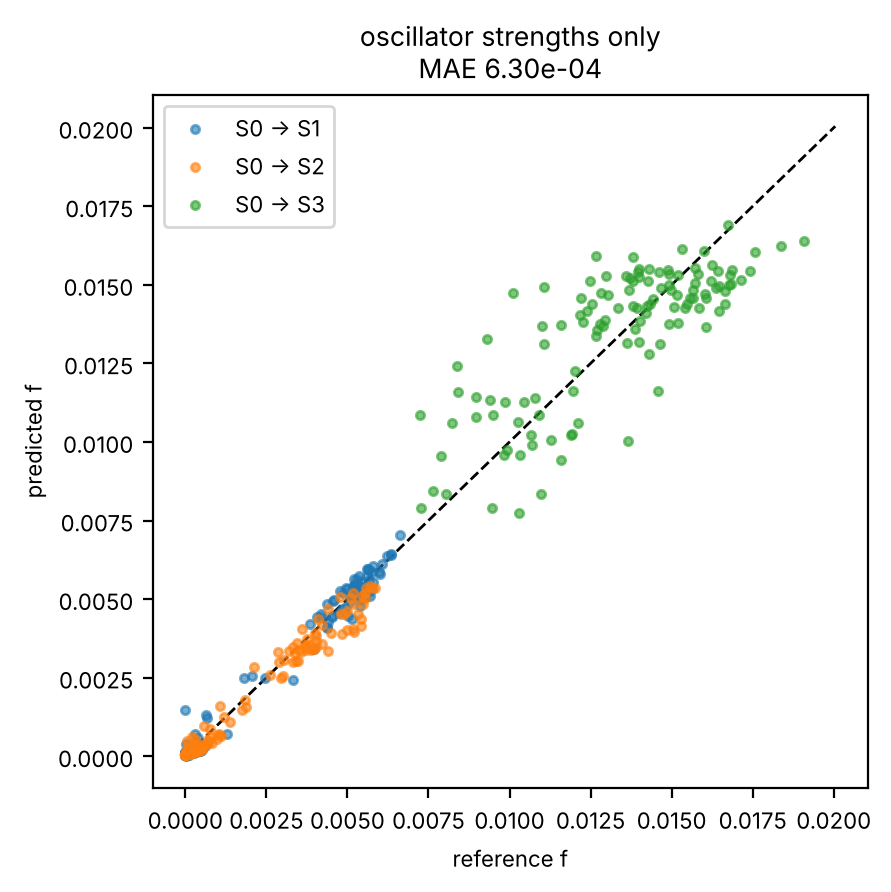

In [6]:
from mace.calculators import ExcitedMACECalculator

osc_test = ase.io.read(RUN / "osc_data" / "test.xyz", ":")
f_ref = np.array([a.info["REF_oscillator_strengths"] for a in osc_test])
calc = ExcitedMACECalculator(str(RUN / "f_only.model"), device=os.environ["DEVICE"])
f_pred = np.array([calc.predict(a)["oscillator_strengths"] for a in osc_test])
print("transitions of the model:", calc.layout.osc_pairs)


def parity(ax, ref, pred, title, err=None):
    for k in range(ref.shape[1]):
        ax.errorbar(ref[:, k], pred[:, k], yerr=None if err is None else err[:, k],
                    fmt="o", ms=3, alpha=0.6, label=f"S0 → S{k + 1}")
    top = max(ref.max(), pred.max()) * 1.05
    ax.plot([0, top], [0, top], "k--", lw=1)
    mae = np.abs(pred - ref).mean()
    ax.set(xlabel="reference f", ylabel="predicted f", title=f"{title}\nMAE {mae:.2e}")
    ax.legend(fontsize=8)


fig, ax = plt.subplots(figsize=(4.5, 4.5))
parity(ax, f_ref, f_pred, "oscillator strengths only")
plt.tight_layout()
plt.show()

## 4. Energies, forces and oscillator strengths together

With energies in the data as well, one model gives excitation energies *and*
oscillator strengths — everything an absorption spectrum needs, and dynamics on top.
Add `REF_oscillator_strengths` to the frames of Tutorial 2 and train on all labels
(a smaller data set and few epochs, to keep it quick).

In [7]:
for name, frames, n in (("all_train.xyz", train, 250), ("all_test.xyz", test, 150)):
    subset = [a.copy() for a in frames[:n]]
    for atoms in subset:
        atoms.info["REF_oscillator_strengths"] = oscillator_strengths(atoms)
    ase.io.write(RUN / name, subset)

In [8]:
%%bash
cd work/oscillator
mace_run_train \
    --name=all_labels \
    --train_file=all_train.xyz --valid_fraction=0.1 --test_file=all_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_oscillator_strengths --compute_nacs --compute_dipoles \
    --E0s=average \
    --r_max=5.0 --hidden_irreps="32x0e + 32x1o" --MLP_irreps=16x0e \
    --num_interactions=2 --correlation=2 \
    --batch_size=10 --max_num_epochs=20 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --dipoles_weight=1 \
    --oscillator_strengths_weight=10 \
    --error_table=EnergyNacsDipoleMAE --device=$DEVICE --default_dtype=float64 \
    > all_labels.out 2>&1
grep -h "Head Default: 7 states" logs/all_labels_run-1.log | head -1 | cut -d" " -f4- | cut -c1-150
grep -A5 "Error-table on TEST" logs/all_labels_run-1.log | tail -n 4

Head Default: 7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=0, dipoles=16, oscillator streng

ths=3 (S0 -> S1..S3)


|       config_type       | MAE E / meV | MAE E / meV / atom | MAE F / meV / A | rel F MAE % | MAE N

ACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles (x1e-3) | MAE f_osc (x1e-3) |
+------------------------

-+-------------+--------------------+-----------------+-------------+------------------+------------

------+---------------------+-------------------+
| Default_Default_Default |      168.9  |         

 56.3      |        154.7    |       6.16  |       349.74     |       N/A        |          25.93   

   |          1.07     |
+-------------------------+-------------+--------------------+-------------

----+-------------+------------------+------------------+---------------------+-------------------+


**An absorption spectrum.** Over an ensemble of geometries (here the test frames,
Wigner-sampled in Tutorial 2), every geometry contributes a stick of height f₀ₖ at
ΔE₀ₖ for each transition; broadening the sticks with Gaussians gives the spectrum
(the nuclear-ensemble approach). Model and reference side by side:

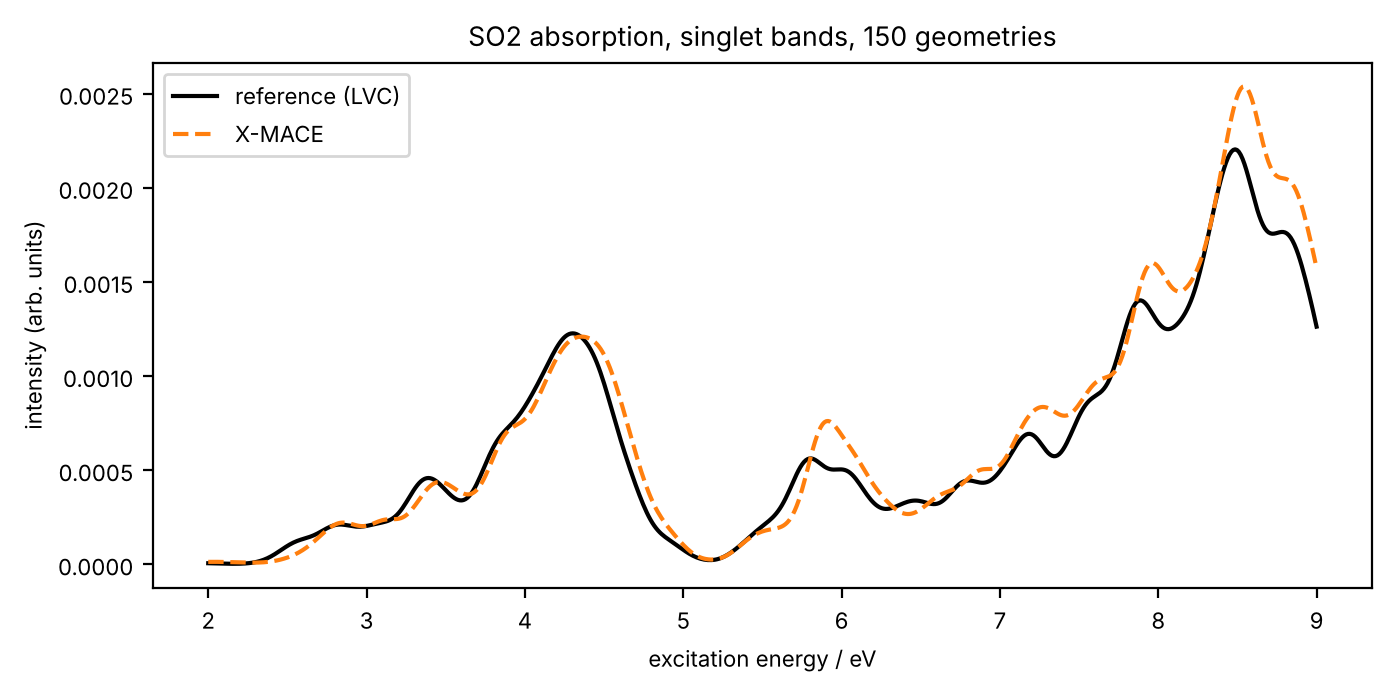

In [9]:
calc = ExcitedMACECalculator(str(RUN / "all_labels.model"), device=os.environ["DEVICE"])
grid = np.linspace(2.0, 9.0, 600)


def spectrum(gaps, strengths, width=0.1):
    bands = strengths[..., None] * np.exp(-((grid - gaps[..., None]) ** 2) / (2 * width**2))
    return bands.reshape(-1, grid.size).sum(0) / len(gaps)


ref_gaps, ref_f, model_gaps, model_f = [], [], [], []
for atoms in test:
    energies = np.asarray(atoms.info["REF_energy"]).reshape(-1)
    ref_gaps.append(energies[1:4] - energies[0])
    ref_f.append(oscillator_strengths(atoms))
    results = calc.predict(atoms)
    model_gaps.append(results["energies"][1:4] - results["energies"][0])
    model_f.append(results["oscillator_strengths"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grid, spectrum(np.array(ref_gaps), np.array(ref_f)), "k", label="reference (LVC)")
ax.plot(grid, spectrum(np.array(model_gaps), np.array(model_f)), "C1--", label="X-MACE")
ax.set(xlabel="excitation energy / eV", ylabel="intensity (arb. units)",
       title="SO2 absorption, singlet bands, 150 geometries")
ax.legend()
plt.tight_layout()
plt.show()

## 5. A committee with uncertainties

Several models that differ only in their random seed agree where they were trained
and disagree elsewhere; their spread is a useful uncertainty. Train three
oscillator-strength models (on a cluster: one array task each, section 7):

In [10]:
%%bash
cd work/oscillator
for SEED in 1 2 3; do
  mace_run_train \
      --name=committee_s$SEED --work_dir=committee/s$SEED --seed=$SEED \
      --train_file=osc_data/train.xyz --valid_file=osc_data/valid.xyz \
      --model=ExcitedMACE --n_energies=$(( $(cat osc_data/n_osc.txt) + 1 )) \
      --compute_oscillator_strengths \
      --E0s="$(cat osc_data/e0s.txt)" --energy_weight=0 --forces_weight=0 \
      --r_max=5.0 --hidden_irreps="32x0e + 32x1o" --MLP_irreps=16x0e \
      --num_interactions=2 --correlation=2 \
      --batch_size=10 --max_num_epochs=30 --lr=0.01 \
      --device=$DEVICE --default_dtype=float64 \
      > committee_s$SEED.out 2>&1
  echo "member $SEED done"
done

member 1 done


member 2 done


member 3 done


`tools/osc_committee.py` evaluates all members on a set of frames (in batches,
without forces), writes the mean (`MACE_oscillator_strengths`) and the spread
(`MACE_oscillator_strengths_std`) into each frame, and, when the frames have reference
values, prints the errors per transition and how well the spread matches them
(`|err|<2std`: share of values within twice the spread, about 0.95 for a
well-calibrated committee; usually lower for three members).

In [11]:
%%bash
cd work/oscillator
python ../../tools/osc_committee.py --model "committee/*/committee_s?.model" \
    --configs osc_data/test.xyz --out pred_osc.xyz --device $DEVICE 2>/dev/null

d.


committee of 3 model(s): ['committee/s1/committee_s1.model', 'committee/s2/committee_s2.model', 'com

mittee/s3/committee_s3.model']


121 frames with predictions written to pred_osc.xyz


 transition      MAE     RMSE     R2  mean ref  mean std |err|<2std
  S0 -> S1     0.0003   0.0004 

 0.974    0.0029    0.0001       0.52


  S0 -> S2     0.0003   0.0004  0.962    0.0022    0.0002       0.62


  S0 -> S3     0.0014   0.0018  0.559    0.0133    0.0005       0.36
        all   0.0007   0.0011
c

orrelation of committee std with |error|: 0.57 (|err|<2std: share of values within twice the spread;

 ~0.95 if calibrated)


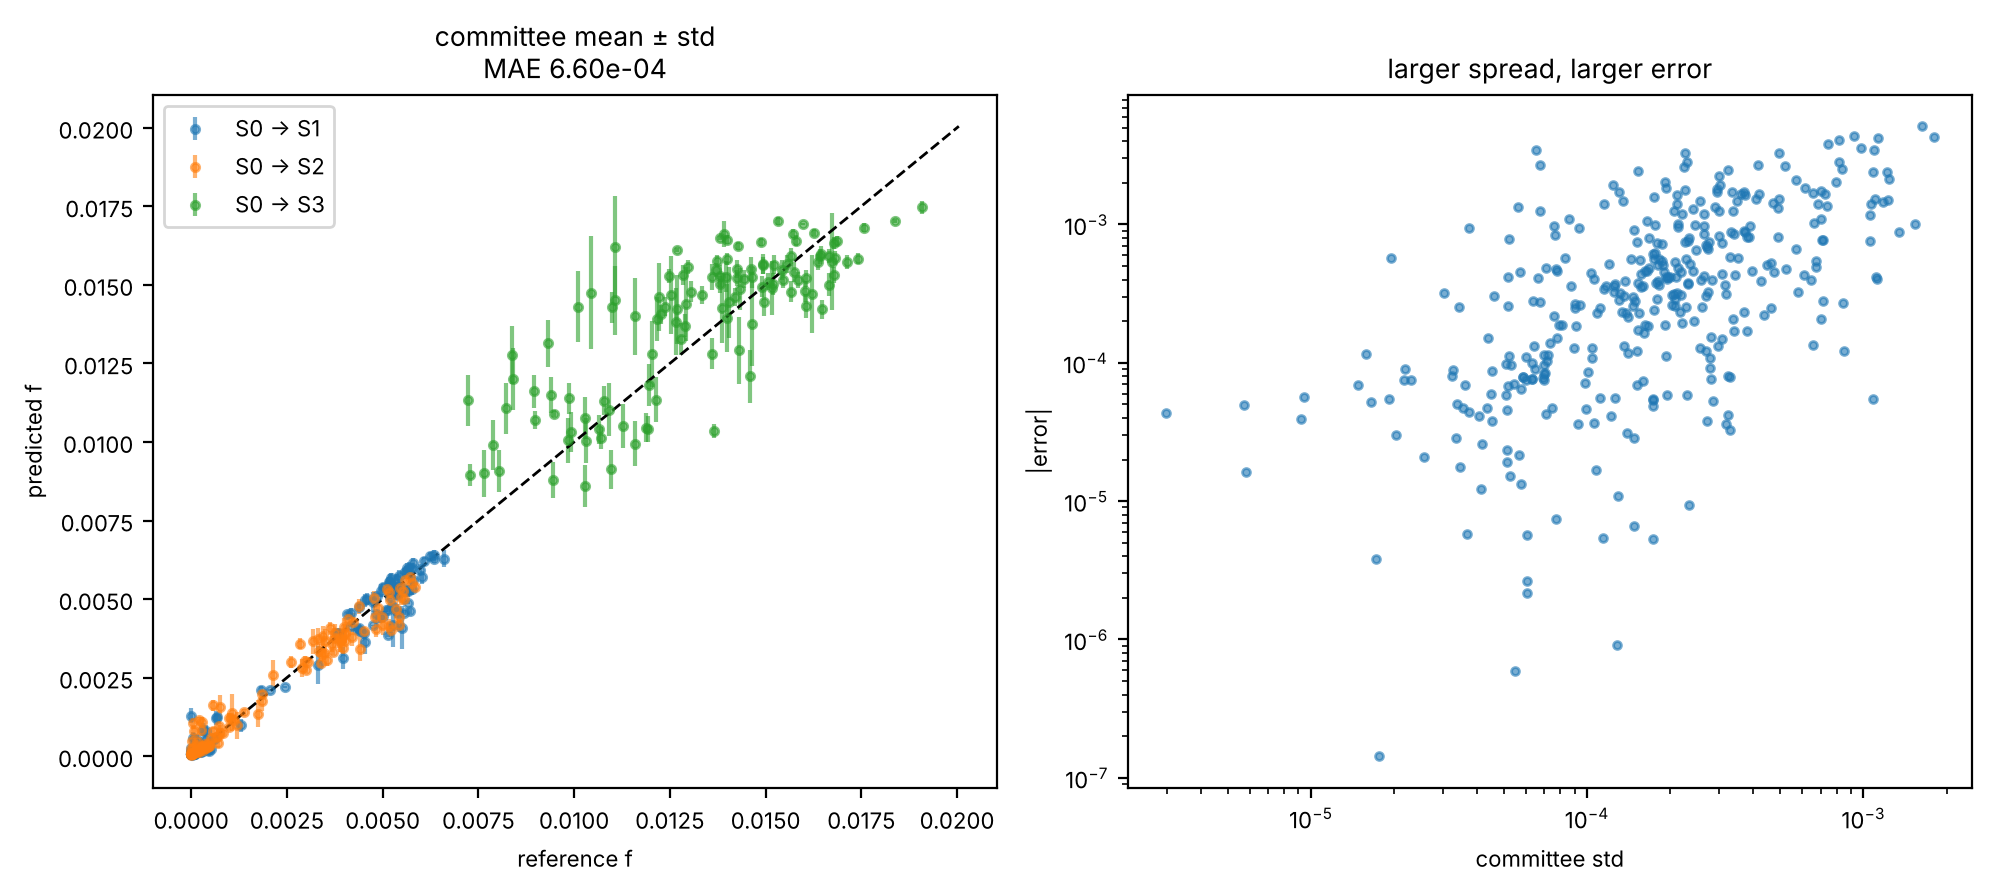

In [12]:
pred = ase.io.read(RUN / "pred_osc.xyz", ":")
mean = np.array([a.info["MACE_oscillator_strengths"] for a in pred])
std = np.array([a.info["MACE_oscillator_strengths_std"] for a in pred])
ref = np.array([a.info["REF_oscillator_strengths"] for a in pred])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
parity(axes[0], ref, mean, "committee mean ± std", err=std)
axes[1].scatter(std.reshape(-1), np.abs(mean - ref).reshape(-1), s=8, alpha=0.6)
axes[1].set(xlabel="committee std", ylabel="|error|", xscale="log", yscale="log",
            title="larger spread, larger error")
plt.tight_layout()
plt.show()

## 6. Adding oscillator strengths to a model you already trained

`work/so2.model` from Tutorial 3 predicts energies, forces and couplings but no
oscillator strengths. Pass it as `--foundation_model` with its options (here
`--states="4 0 3"` and its couplings) plus `--compute_oscillator_strengths`:
X-MACE recognises that only the oscillator strengths are new, keeps **every** other
weight, shift and scale, and adds oscillator-strength readouts.

With `--train_only_oscillator_strengths` only those new readouts train; the
energies, forces and couplings stay exactly as they were. So the data may have
oscillator strengths only, e.g. the f-only files of section 2 (no NACs etc. needed:
missing labels have weight 0, and all other loss weights are 0 here). The test set
with all labels shows that nothing else changed:

In [13]:
%%bash
cd work/oscillator
mace_run_train \
    --name=so2_plus_f \
    --foundation_model=../so2.model \
    --train_file=osc_data/train.xyz --valid_file=osc_data/valid.xyz --test_file=all_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --compute_oscillator_strengths --train_only_oscillator_strengths \
    --E0s="$(cat osc_data/e0s.txt)" \
    --energy_weight=0 --forces_weight=0 --nacs_weight=0 --socs_weight=0 --dipoles_weight=0 \
    --batch_size=10 --max_num_epochs=10 --lr=0.01 --seed=1 \
    --error_table=EnergyNacsDipoleMAE --device=$DEVICE --default_dtype=float64 \
    > so2_plus_f.out 2>&1
grep -h "Adding oscillator strengths\|Training only\|Parameters:" logs/so2_plus_f_run-1.log | cut -d" " -f4- | cut -c1-150
echo "Tutorial 3 model:"; grep -A5 "Error-table on TEST" ../training/logs/so2_run-1.log | tail -n 2 | head -n 1
echo "with oscillator strengths added:"; grep -A5 "Error-table on TEST" logs/so2_plus_f_run-1.log | tail -n 2 | head -n 1

Adding oscillator strengths to the excited-state foundation model: backbone, adapter, energy and cou

pling readouts, shifts and scales keep their weigh
Training only the oscillator-strength readouts; e

very other weight (energies, forces, couplings) stays as it is
Parameters: 143744 in total, 752 trai

nable


Tutorial 3 model:
| Default_Default_Default |        4.3  |           1.4      |         45.6    |  

     1.82  |        86.97     |      2183.22     |           7.01      |
with oscillator strengths a

dded:


| Default_Default_Default |        4.3  |           1.4      |       N/A       |     N/A     |      

  86.97     |      2183.22     |           7.01      |          0.76     |


Energies, NACs, SOCs and dipoles have exactly the errors of the Tutorial 3 model,
and the model now gives oscillator strengths too (last column). Forces show `N/A`
only because, with every force weight 0, this run computes none; the model still
has them. Without `--train_only_oscillator_strengths` all weights train, which
needs data with all labels (and usually a lower learning rate) to keep the energies
where they were. Models saved before oscillator strengths existed load and run
unchanged.

## 7. On a GPU cluster: a committee on MACE-POLAR-1-M

`tools/train_committee_osc.slurm` trains a committee of three oscillator-strength
models on a large data set prepared as in section 2: MACE-POLAR-1-M as backbone with
LoRA, stage two, one array task (one GPU) per seed. The core of it:

```bash
torchrun --standalone --nproc_per_node="$NGPU" -m mace.cli.run_train \
  --distributed --launcher=torchrun --device=cuda \
  --name="$NAME" --work_dir="runs_osc/$NAME" --seed="$SEED" \
  --train_file="$DATA/train.xyz" --valid_file="$DATA/valid.xyz" --test_file="$DATA/test.xyz" \
  --model=ExcitedMACE --n_energies="$N_STATES" --compute_oscillator_strengths \
  --foundation_model=polar-1-m --excited_long_range=shared --multiheads_finetuning=False \
  --lora=True --lora_rank=4 --lora_alpha=1 \
  --E0s=foundation \
  --energy_weight=0 --forces_weight=0 --oscillator_strengths_weight=10 \
  --default_dtype=float32 --batch_size="$BATCH" --valid_batch_size=64 \
  --lr=0.001 --max_num_epochs="$EPOCHS" --patience=20 --ema --ema_decay=0.99 \
  --stage_two --start_stage_two="$STAGE_TWO" --swa_lr=1e-4 \
  --swa_energy_weight=0 --swa_forces_weight=0 \
  --error_table=EnergyNacsDipoleMAE --num_workers=4 --restart_latest
```

Fill in partition, account and environment, then:

```bash
python tutorials/xmace/tools/prepare_osc_data.py your_data.xyz --out_dir osc_data
sbatch tutorials/xmace/tools/train_committee_osc.slurm      # from the folder with osc_data/
squeue -u $USER; tail -f slurm-xmace_osc_polar_m-1-*.out
python tutorials/xmace/tools/osc_committee.py --model "runs_osc/*/*_stagetwo.model" \
    --configs osc_data/test.xyz --out pred_osc.xyz
```

Points to keep in mind:

* **Stage two** needs `--swa_forces_weight=0` (and `--swa_energy_weight=0`) too;
  otherwise forces are computed again from stage two on.
* **`ExcitedMACE`, not the autoencoder:** the autoencoder orders energies, which this
  data does not have.
* **`--E0s=foundation`**: the data has no energies to average.
* **The energies of such a model** are the foundation's untrained ones: do not use
  them for dynamics or gaps.
* With LoRA the line "Model with LoRA has N trainable parameters" counts all
  parameters; the line after it ("… in total, M trainable") is the true count.
* Batch size: `--batch_size` is per GPU; it must be smaller than the training set.
  Without forces each step is cheap, so large batches (32–64) are fine.

## 8. Checking your installation, and troubleshooting

Oscillator strengths need an X-MACE version with the commits *Learn oscillator
strengths directly* and *Oscillator strengths: data without energies or forces*.
Check:

In [14]:
import mace
from mace.modules.excited_loss import oscillator_strengths_loss  # noqa: F401
from mace.data.utils import load_from_xyz
from mace import data as mace_data

print("X-MACE from:", Path(mace.__file__).parent)
keys = mace_data.KeySpecification.from_defaults()
keys.update(info_keys={"oscillator_strengths": "REF_oscillator_strengths"})
_, configs = load_from_xyz(str(RUN / "osc_data" / "valid.xyz"), key_specification=keys)
print(f"{len(configs)} frames with oscillator strengths only load; first:",
      configs[0].properties["oscillator_strengths"])

X-MACE from: <repository>/mace
81 frames with oscillator strengths only load; first: [0.00423824 0.00020544 0.01291707]


From a terminal, in the repository: `git log --oneline -3` shows the commits;
`grep -n has_excited mace/data/utils.py` finds the loader fix; and
`pytest -q tests/test_excited_oscillator_strengths.py` runs the tests (about two
minutes). The path printed above must be the copy you updated; if not, run
`pip install -e .` there.

| message | cause | fix |
|---|---|---|
| `None of 'REF_energy', 'REF_forces', and 'dipole' found` | X-MACE without the loader fix | update (above) |
| `Expected xyz header but got: invalid literal for int() … '﻿…'` | byte-order mark (file saved on Windows) | `prepare_osc_data.py`, or `sed -i '1s/^\xEF\xBB\xBF//; s/\r$//' file.xyz` |
| `expected 5 oscillator strengths … found 6` | `--n_energies` / `--osc_num` do not match the data | `--n_energies` = number of values + 1 |
| `fewer than --batch_size` | training set smaller than one batch | lower `--batch_size` |
| the log says `forces … not computed` is missing and training is slow | a force weight > 0 (also `--swa_forces_weight`) | set both to 0 for f-only data |
| f values read as energies | f stored under `REF_energy` | convert with `prepare_osc_data.py` |
| energies of a trained model get worse when adding f | all weights train on f | `--train_only_oscillator_strengths` |

## Summary

* `--compute_oscillator_strengths` learns f(S0 → Sk) directly: invariant, ≥ 0,
  scaled per transition by the rms of the data.
* Data with oscillator strengths only: `--energy_weight=0 --forces_weight=0`
  (and the stage-two weights), `--E0s` as a dictionary or from a foundation model; no
  forces are computed.
* `tools/prepare_osc_data.py` converts and splits, `tools/osc_committee.py` gives
  committee means and uncertainties, `tools/train_committee_osc.slurm` trains a
  committee on MACE-POLAR-1-M.
* A trained model gains oscillator strengths with `--foundation_model` and
  `--compute_oscillator_strengths`, keeping all its other weights;
  `--train_only_oscillator_strengths` trains only the new readouts, from f-only data.

**Next:** [Tutorial 9](09_more_models.ipynb): committees, the autoencoder, backbones and
heads, Stage Two and restarts, and the Python API.